In [106]:
from pytweezer.servers.device_client import get_device
from pytweezer.drivers.motmaster import MotMasterInterface
from pytweezer.drivers.imagemX2 import ImagEMX2Camera
from pytweezer.drivers.slm import SLM
import numpy as np
import pytweezer.helper_scripts.phasemask as pm

In [107]:
slm = get_device("Rb SLM")

## Generate Initial and Final Array Hologram

In [108]:
dx, dy = 8.0, 12.0
PM = pm.OptimisationBasedPhasemaskGeneratorGPU(
                 wavelength_um=0.852,
                 focal_length_mm=17.3,
                 slm_pitch_um=17,
                 slm_res=(1024,1024),
                 input_beam_waist_mm=16,
                 fresnel_f_mm=1105,
                 blaze_dx_dy_um=(48.0, 6.0),
                 zernike_coeff_dict={5:1.195, 6:0.725, 7:0.970, 8:0.478, 9:-1.091, 10:0.303, 11:0.021, 12:0.072, 13:0.049})


gauss2d = lambda x, y, A, x0, y0, sx, sy, offset: (A * np.exp(-(((x - x0) ** 2) / (2 * sx ** 2) + ((y - y0) ** 2) / (2 * sy ** 2)))) + offset
A, x0, y0, sx, sy, offset = [-2.14197604e+03, -1.11443850e+01 - dx, 2.09919600e+00 - dy, 2.95002910e+03, 2.64281503e+03, 2.14239505e+03]

--- System Configuration ---
SLM Plane Width: 17.41 mm
SLM Plane Height: 17.41 mm
Focal Plane Resolution x (pixel size): 0.8467 um
Focal Plane Resolution y (pixel size): 0.8467 um
Focal Plane Width: 867.04 um
Focal Plane Height: 867.04 um
Fresnel Lens Focal Length: 1105.00 mm
Blazed Grating Displacement (dx, dy): (48.0, 6.0) um


In [109]:
W1 = np.ones((8,8))
spacing_um = 5.0

w_n, theta_n, x_n1, y_n1 = PM.generate_weighted_array(W1, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n1, y_n1, A, x0, y0, sx, sy, offset)

terms1 = [w_n, theta_n, x_n1, y_n1]
pm_array1, terms1, _ = PM.superposition_optimization(terms1, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x8
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval ---
Iteration 000 | Mean-Squared Error: 4.45e-05 | Uniformity: 50.59% | Min/Max ratio: 0.083
Iteration 010 | Mean-Squared Error: 2.39e-07 | Uniformity: 85.99% | Min/Max ratio: 0.594
Iteration 020 | Mean-Squared Error: 3.01e-08 | Uniformity: 86.79% | Min/Max ratio: 0.581
Iteration 030 | Mean-Squared Error: 3.19e-08 | Uniformity: 86.60% | Min/Max ratio: 0.584
Iteration 040 | Mean-Squared Error: 1.21e-08 | Uniformity: 86.66% | Min/Max ratio: 0.596
Iteration 050 | Mean-Squared Error: 1.68e-08 | Uniformity: 86.81% | Min/Max ratio: 0.596
Iteration 060 | Mean-Squared Error: 2.44e-08 | Uniformity: 86.84% | Min/Max ratio: 0.599
Iteration 070 | Mean-Squared Error: 6.34e-09 | Uniformity: 86.76% | Min/Max ratio: 0.601
Iteration 080 | Mean-Squared Error: 8.11e-09 | Uniformity: 86.69% | Min/Max ratio: 0.603
Iteration 090 | Mean-Squared Error: 3.97e-09 | Uniformity: 86.77% | Min/Max ratio: 0.602
Iterati

In [110]:
PM = pm.OptimisationBasedPhasemaskGeneratorGPU(
                 wavelength_um=0.852,
                 focal_length_mm=17.3,
                 slm_pitch_um=17,
                 slm_res=(1024,1024),
                 input_beam_waist_mm=16,
                 fresnel_f_mm=1072,
                 blaze_dx_dy_um=(48.0, 6.0),
                 zernike_coeff_dict={5:1.195, 6:0.725, 7:0.970, 8:0.478, 9:-1.091, 10:0.303, 11:0.021, 12:0.072, 13:0.049})


pm_composite = PM.superimpose([pm_array1, PM.fresnel, PM.blaze])
pm_composite_uint8 = PM.transform_phase_8bit(pm_composite).get()
slm.update_mask(pm_composite_uint8)

--- System Configuration ---
SLM Plane Width: 17.41 mm
SLM Plane Height: 17.41 mm
Focal Plane Resolution x (pixel size): 0.8467 um
Focal Plane Resolution y (pixel size): 0.8467 um
Focal Plane Width: 867.04 um
Focal Plane Height: 867.04 um
Fresnel Lens Focal Length: 1072.00 mm
Blazed Grating Displacement (dx, dy): (48.0, 6.0) um


In [111]:
PM = pm.OptimisationBasedPhasemaskGeneratorGPU(
                 wavelength_um=0.852,
                 focal_length_mm=17.3,
                 slm_pitch_um=17,
                 slm_res=(1024,1024),
                 input_beam_waist_mm=16,
                 fresnel_f_mm=1072,
                 blaze_dx_dy_um=(48.0, 6.0),
                 zernike_coeff_dict={5:1.195, 6:0.725, 7:0.970, 8:0.478, 9:-1.091, 10:0.303, 11:0.021, 12:0.072, 13:0.049})


pm_composite = PM.superimpose([pm_array1, PM.fresnel, PM.blaze])
pm_composite_uint8 = PM.transform_phase_8bit(pm_composite).get()
slm.update_mask(pm_composite_uint8)

--- System Configuration ---
SLM Plane Width: 17.41 mm
SLM Plane Height: 17.41 mm
Focal Plane Resolution x (pixel size): 0.8467 um
Focal Plane Resolution y (pixel size): 0.8467 um
Focal Plane Width: 867.04 um
Focal Plane Height: 867.04 um
Fresnel Lens Focal Length: 1072.00 mm
Blazed Grating Displacement (dx, dy): (48.0, 6.0) um


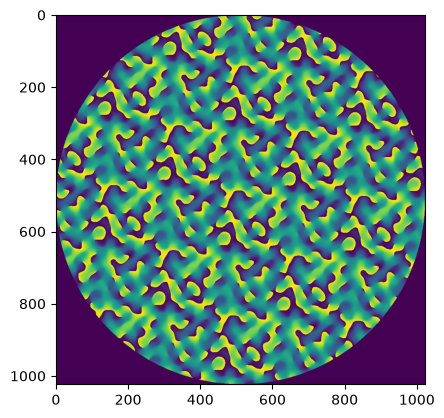

In [112]:
def superimpose_pupil(phasemask, pupil_radius_um, pupil_blaze_dx_dy_um=(0.0, 0.0)):
        """
        Applies a circular pupil function to the phasemask.
        
        Parameters:
        - phasemask (np.ndarray): The input phase mask in radians.
        - pupil_radius_um (float): The radius of the circular pupil in microns.
        - pupil_blaze_dx_dy_um (tuple): The displacement of the pupil from the blaze in microns.
        
        Returns:
        - masked_phasemask (np.ndarray): The phase mask after applying the pupil function.
        """
        X, Y = np.meshgrid(PM.x_slm, PM.y_slm)
        R = np.sqrt(X**2 + Y**2)
        pupil_mask = (R <= pupil_radius_um).astype(float)
        core_mask = (R > pupil_radius_um).astype(float)
        offset_blaze = PM.generate_blazed_grating_phasemask(pupil_blaze_dx_dy_um[0], pupil_blaze_dx_dy_um[1])*core_mask
    
        return phasemask * pupil_mask + offset_blaze

composite_pupil = superimpose_pupil(pm_array1, pupil_radius_um=PM.Lx_slm/2, pupil_blaze_dx_dy_um=(0.0, 0.0))
plt.imshow(composite_pupil.get(), cmap='viridis')

In [113]:
fresnel = PM.generate_fresnel_lens_phasemask(1125)
pm_composite = PM.superimpose([pm_array1, fresnel, PM.blaze])
pm_composite_pupil = superimpose_pupil(pm_composite, pupil_radius_um=PM.Lx_slm/2, pupil_blaze_dx_dy_um=(100.0, 0.0))
pm_composite_uint8 = PM.transform_phase_8bit(pm_composite_pupil).get()
slm.update_mask(pm_composite_uint8)

## Baseline - Load and Image Initial Array

In [114]:
from pytweezer.experiment.experiment_parameter_manager import ExpParameterManager
ExpParams = ExpParameterManager()
import pytweezer.analysis.analysis as an

In [115]:
exp: MotMasterInterface = get_device("Rb MOTMaster")
hamcam: ImagEMX2Camera = get_device("Rb HamCam")

In [116]:
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)
exp.set_motmaster_experiment("RbTweezerBasic2026_2")

In [117]:
ExpParams.save_parameters()
exp_params = ExpParams.load_parameters()['motmaster_parameters']
for key, value in exp_params.items():
    print(f"{key}: {value}")

Parameters saved.
tMOTLoadCoolVCO: 4.2631578947368425
tMOTLoadRepVCO: 1.8421052631578947
tMolCoolVCO1: 3.0
tMolRepVCO1: 3.11
tMolCoolVVA1: 1.0
tMolRepVVA1: 0.53
tMolCoolVCO2: 0.0
tMolRepVCO2: 3.26
tMolCoolVVA2: 1.0
tMolRepVVA2: 0.75
tMOTShimXccValue: 0.017274499890946874
tMOTShimYccValue: 1.38581476439688
tMOTShimZccValue: -0.4844836103904361
tMOTLoadRepVVA: 0.6526315789473685
tMOTLoadCoolVVA: 0.9210526315789475
tImgCoolVCO: 3.0
tImgCoolVVA: 1.5
tMolassesShimXccValue: 5.4965
tMolassesShimYccValue: 3.6861
tMolassesShimZccValue: 0.114


In [118]:
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)
exp.set_motmaster_experiment("RbTweezerBasic2026_2")

hamcam.set_trigger_source("ext")
hamcam.set_external_exposure_mode()
hamcam.enable_em_gain(True)
hamcam.enable_direct_em_gain(True)
hamcam.set_sensitivity(600)
hamcam.timeout = 60*5
X0, Y0, WIDTH, HEIGHT = 110, 220, 256, 256
hamcam.set_roi(X0, WIDTH, Y0, HEIGHT)

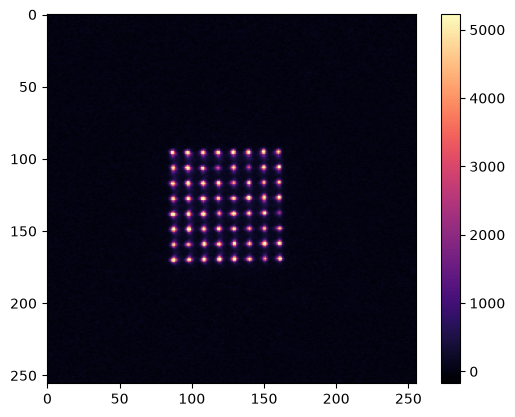

In [119]:
# Experiment and camera setup
n_iterations = 100
exp.set_motmaster_experiment("RbTweezerBasic2026_2")
exp.set_iterations(1)
hamcam.setup_acquisition("snap", 2)
imgs1, imgs2 = [], []
for i in range(n_iterations):
    hamcam.start_acquisition()
    exp.start_motmaster_experiment({
        "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
        "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
        "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"),
        "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
        "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"),
        "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
        "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"),
        "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
        "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
        "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
        "tTweezerSetVVA0": 0.0, "tTweezerSetVVA1": 0.0,
        "BackgroundDrop": 1})
    

    img1, img2 = hamcam.acquire_n_frames(2, broadcast=True)
    imgs1.append(img1)
    imgs2.append(img2)

img_average = an.tweezer_show_bg_subtracted(imgs1, imgs2, cmap='magma', show=True, vmaxfactor=0.6, show_grid=True)



In [120]:
ExpParams.set_parameter("conversion_factor", 0.009508957628343926)
ExpParams.set_parameter("conversion_offset", 1916.7664794921875)
ExpParams.save_parameters()


Parameter 'conversion_factor' set to 0.009508957628343926.
Parameter 'conversion_offset' set to 1916.7664794921875.
Parameters saved.


Looking for trap sites...
64 Atoms Detected.
Parameter 'x_centre' set to 123.390625.
Parameter 'y_centre' set to 132.015625.
Parameters saved.


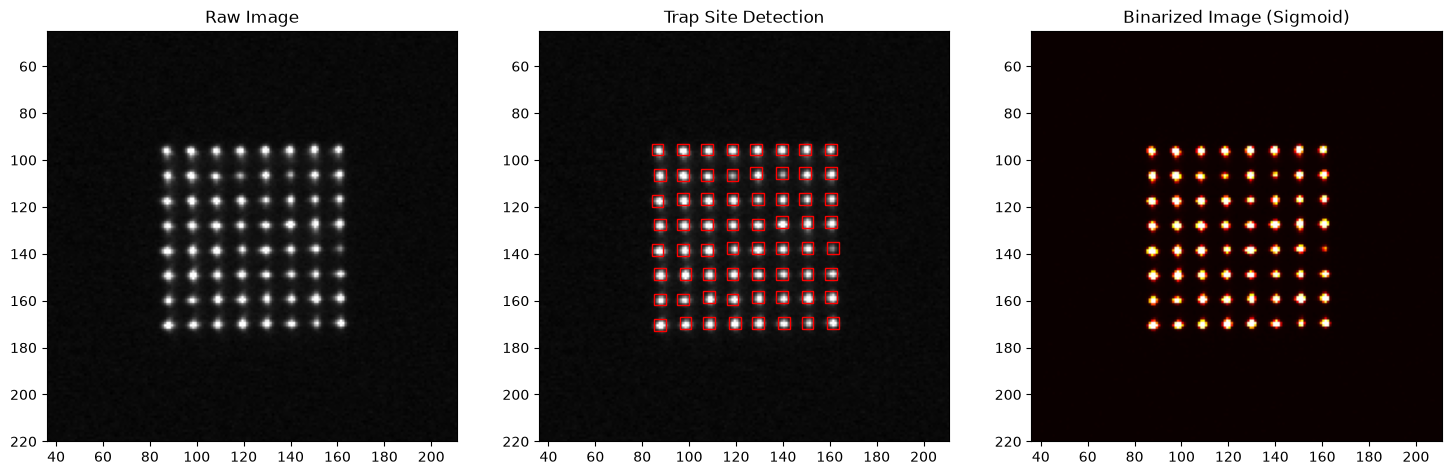

Trap (0) Loading Probability : 46.00 %
Trap (1) Loading Probability : 54.00 %
Trap (2) Loading Probability : 47.00 %
Trap (3) Loading Probability : 53.00 %
Trap (4) Loading Probability : 52.00 %
Trap (5) Loading Probability : 46.00 %
Trap (6) Loading Probability : 53.00 %
Trap (7) Loading Probability : 53.00 %
Trap (8) Loading Probability : 47.00 %
Trap (9) Loading Probability : 45.00 %
Trap (10) Loading Probability : 30.00 %
Trap (11) Loading Probability : 40.00 %
Trap (12) Loading Probability : 29.00 %
Trap (13) Loading Probability : 41.00 %
Trap (14) Loading Probability : 50.00 %
Trap (15) Loading Probability : 48.00 %
Trap (16) Loading Probability : 35.00 %
Trap (17) Loading Probability : 30.00 %
Trap (18) Loading Probability : 42.00 %
Trap (19) Loading Probability : 35.00 %
Trap (20) Loading Probability : 46.00 %
Trap (21) Loading Probability : 46.00 %
Trap (22) Loading Probability : 57.00 %
Trap (23) Loading Probability : 43.00 %
Trap (24) Loading Probability : 43.00 %
Trap (25) 

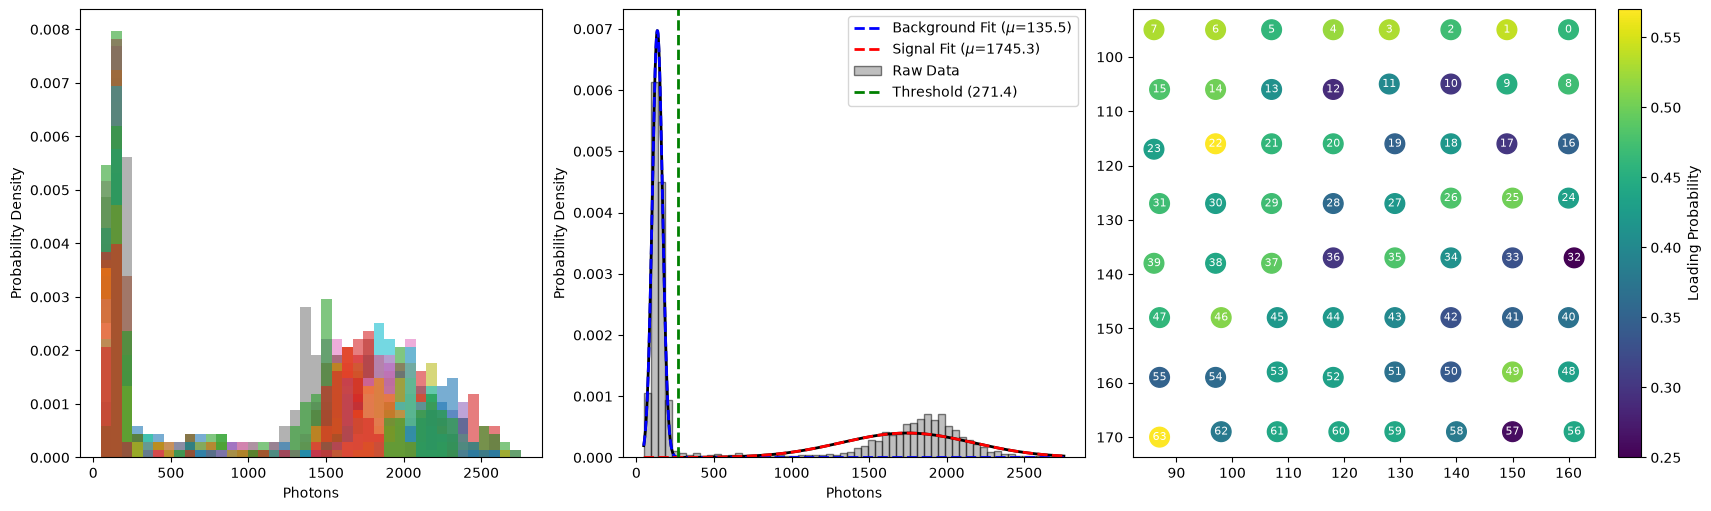

In [121]:
feature_size, window = 10, 5
grid_positions, detection_threshold = an.detect_trap_sites(img_average, 8*8, detection_step=100)
an.set_array_centre(grid_positions)
grid_positions = an.index_grid_positions(grid_positions, x_n1, y_n1)
an.visualize_results(img_average, grid_positions, margin=50, window_size=window, threshold=detection_threshold, vmaxfactor=0.5, bin_sharpness=20, bin_thresh_factor=0.9)
imgs_n_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs1]
photons, loading_probabilities, threshold_1, fidelity = an.get_array_loading_statistics(imgs_n_filtered, grid_positions, threshold=100, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=True, verbose=True, show_site_labels=True)

In [122]:
## Routine MOT Shim Coil Optimisation
from skopt.space import Real, Integer
from skopt.utils import use_named_args
from skopt import Optimizer

In [123]:
"""
tMOTShimXccValue: 0.017274499890946874
tMOTShimYccValue: 1.38581476439688
tMOTShimZccValue: -0.4844836103904361
"""
# --- 1. Define the Experimental Search Space ---
dimensions = [
    Real(name='tMolassesShimXccValue', low=-0.983, high=1.017),
    Real(name='tMolassesShimYccValue', low=0.386, high=2.386),
    Real(name='tMolassesShimZccValue', low=-1.484, high=0.516)
]

# Experiment and camera setup
n_iterations = 20
exp.set_motmaster_experiment("RbTweezerBasic2026_2")
exp.set_iterations(1)
hamcam.setup_acquisition("snap", 2)

@use_named_args(dimensions=dimensions)
def tweezer_exp_objective(tMolassesShimXccValue, tMolassesShimYccValue, tMolassesShimZccValue):
    motmaster_parameters = {
        "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
        "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
        "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"),
        "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
        "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"),
        "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
        "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"),
        "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
        "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
        "tMolassesShimXccValue": tMolassesShimXccValue, "tMolassesShimYccValue": tMolassesShimYccValue, "tMolassesShimZccValue": tMolassesShimZccValue,
        "BackgroundDrop": 1, "tDropDuration": 3}

    imgs1, imgs2 = [], []
    for i in range(n_iterations):
        hamcam.start_acquisition()
        exp.start_motmaster_experiment(motmaster_parameters)
        img1, img2 = hamcam.acquire_n_frames(2, broadcast=True)
        imgs1.append(img1)
        imgs2.append(img2)

    imgs_filtered_1 = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs1]
    imgs_filtered_2 = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs2]
    _, loading_probabilities, _, _ = an.get_array_loading_statistics(imgs_filtered_1, grid_positions, threshold_detection=False, threshold=threshold_1, binning=60, show_histogram=False, verbose=False)

    mean_loading_probability = np.mean(loading_probabilities)
    mean_survival_prob = an.extract_survival_probability(imgs_filtered_1, imgs_filtered_2, grid_positions, window_size=window, threshold=threshold_1)

    if mean_loading_probability < 0.5:
        measured_loss = 1.0 - mean_loading_probability
    else:
        measured_loss = 0.5 - mean_survival_prob

    print(f"Parameters: tMolassesShimXccValue = {tMolassesShimXccValue:.2f}, tMolassesShimYccValue = {tMolassesShimYccValue:.2f}, tMolassesShimZccValue = {tMolassesShimZccValue:.2f}  |  Mean Loading Probability = {mean_loading_probability:.4f}, Mean Survival Probability = {mean_survival_prob:.4f}")
    return measured_loss



print("Starting Bayesian Optimization with dynamic exploration...")

n_calls = 50
n_initial_points = 10
xi_start = 0.100
xi_end = 0.001

opt = Optimizer(
    dimensions=dimensions,
    n_initial_points=n_initial_points,
    acq_func='EI',
    random_state=50
)

# Custom optimization loop
for i in range(n_calls):
    current_xi = xi_start - (xi_start - xi_end) * (i / (n_calls - 1))
    opt.acq_func_kwargs = {'xi': current_xi}
    suggested_params = opt.ask()
    loss = tweezer_exp_objective(suggested_params)
    result = opt.tell(suggested_params, loss)
    print(f"Iteration {i+1}/{n_calls} (xi = {current_xi:.4f})")
    print(f"  Current score: {(1-loss):.4f}")
    print(f"  Best score: {(1-result.fun):.4f}\n")

# --- 4. Analyze the Results ---
print("\n" + "="*40)
print("Optimization Complete!")
print("="*40)

high_score = 1 - result.fun
best_params = result.x

print(f"Best Parameters Found:")
for dim, value in zip(dimensions, best_params):
    print(f"  {dim.name}: {value:.4f}")

Starting Bayesian Optimization with dynamic exploration...
Parameters: tMolassesShimXccValue = -0.72, tMolassesShimYccValue = 0.53, tMolassesShimZccValue = -0.26  |  Mean Loading Probability = 0.3016, Mean Survival Probability = 0.0836
Iteration 1/50 (xi = 0.1000)
  Current score: 0.3016
  Best score: 0.3016

Parameters: tMolassesShimXccValue = -0.94, tMolassesShimYccValue = 0.69, tMolassesShimZccValue = 0.43  |  Mean Loading Probability = 0.4461, Mean Survival Probability = 0.1085
Iteration 2/50 (xi = 0.0980)
  Current score: 0.4461
  Best score: 0.4461



C:\Users\tweez\ColdMatter\pytweezer\pytweezer\analysis\analysis.py:1015: RuntimeWarning: Mean of empty slice
  mu_sig = tot_photon_array[tot_photon_array >= threshold].mean()
c:\Users\tweez\ColdMatter\pytweezer\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\tweez\ColdMatter\pytweezer\pytweezer\analysis\analysis.py:1017: RuntimeWarning: Degrees of freedom <= 0 for slice
  var_sig = tot_photon_array[tot_photon_array >= threshold].var()
c:\Users\tweez\ColdMatter\pytweezer\.venv\Lib\site-packages\numpy\_core\_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\Users\tweez\ColdMatter\pytweezer\.venv\Lib\site-packages\numpy\_core\_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Parameters: tMolassesShimXccValue = 0.63, tMolassesShimYccValue = 0.87, tMolassesShimZccValue = -0.83  |  Mean Loading Probability = 0.0297, Mean Survival Probability = 0.0000
Iteration 3/50 (xi = 0.0960)
  Current score: 0.0297
  Best score: 0.4461

Parameters: tMolassesShimXccValue = -0.10, tMolassesShimYccValue = 0.66, tMolassesShimZccValue = -0.29  |  Mean Loading Probability = 0.2672, Mean Survival Probability = 0.0616
Iteration 4/50 (xi = 0.0939)
  Current score: 0.2672
  Best score: 0.4461

Parameters: tMolassesShimXccValue = 0.97, tMolassesShimYccValue = 0.56, tMolassesShimZccValue = -0.90  |  Mean Loading Probability = 0.0102, Mean Survival Probability = 0.0000
Iteration 5/50 (xi = 0.0919)
  Current score: 0.0102
  Best score: 0.4461

Parameters: tMolassesShimXccValue = -0.50, tMolassesShimYccValue = 1.42, tMolassesShimZccValue = -1.39  |  Mean Loading Probability = 0.0000, Mean Survival Probability = 0.0000
Iteration 6/50 (xi = 0.0899)
  Current score: 0.0000
  Best score: 0.

KeyboardInterrupt: 

In [124]:
"""
tImgCoolVCO: 3.0
tImgCoolVVA: 1.5
"""
# --- 1. Define the Experimental Search Space ---
dimensions = [  
    Real(name='tImgCoolVCO', low=0.2, high=4.0),
    Real(name='tImgCoolVVA', low=0.4, high=2.0),
]

# Experiment and camera setup
n_iterations = 20
exp.set_motmaster_experiment("RbTweezerBasic2026_2")
exp.set_iterations(1)
hamcam.setup_acquisition("snap", 2)

@use_named_args(dimensions=dimensions)
def tweezer_exp_objective(tImgCoolVCO, tImgCoolVVA):
    hamcam.start_acquisition()
    motmaster_parameters = {
        "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
        "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
        "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"),
        "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
        "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"),
        "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
        "tImgCoolVCO1": tImgCoolVCO, "tImgCoolVVA1": tImgCoolVVA,
        "tImgCoolVCO2": tImgCoolVCO, "tImgCoolVVA2": tImgCoolVVA,
        "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
        "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
        "BackgroundDrop": 0}

    imgs1, imgs2 = [], []
    for i in range(n_iterations):
        hamcam.start_acquisition()
        exp.start_motmaster_experiment(motmaster_parameters)
        img1, img2 = hamcam.acquire_n_frames(2, broadcast=True)
        imgs1.append(img1)
        imgs2.append(img2)

    imgs_filtered_1 = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs1]
    imgs_filtered_2 = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs2]
    _, loading_probabilities, _, fidelity = an.get_array_loading_statistics(imgs_filtered_1, grid_positions, threshold_detection=True, threshold=threshold_1, binning=60, show_histogram=False, verbose=False)    


    mean_loading_probability = np.mean(loading_probabilities)
    mean_survival_prob = an.extract_survival_probability(imgs_filtered_1, imgs_filtered_2, grid_positions, window_size=window, threshold=threshold_1)

    if fidelity > 0.99:
        measured_loss = 1.0 - mean_survival_prob
    else:
        measured_loss = 1.0 - fidelity * 0.8

    print(f"Parameters: tImgCoolVCO = {tImgCoolVCO:.2f}, tImgCoolVVA = {tImgCoolVVA:.2f}  |  Mean Loading Probability = {mean_loading_probability:.4f}, Mean Survival Probability = {mean_survival_prob:.4f}, Fidelity = {fidelity:.4f}")
    return measured_loss


print("Starting Bayesian Optimization with dynamic exploration...")

n_calls = 10
n_initial_points = 10
xi_start = 0.100
xi_end = 0.001

opt = Optimizer(
    dimensions=dimensions,
    n_initial_points=n_initial_points,
    acq_func='EI',
    random_state=50
)

# Custom optimization loop
for i in range(n_calls):
    current_xi = xi_start - (xi_start - xi_end) * (i / (n_calls - 1))
    opt.acq_func_kwargs = {'xi': current_xi}
    suggested_params = opt.ask()
    loss = tweezer_exp_objective(suggested_params)
    result = opt.tell(suggested_params, loss)
    print(f"Iteration {i+1}/{n_calls} (xi = {current_xi:.4f})")
    print(f"  Current score: {(1-loss):.4f}")
    print(f"  Best score: {(1-result.fun):.4f}\n")

# --- 4. Analyze the Results ---
print("\n" + "="*40)
print("Optimization Complete!")
print("="*40)

high_score = 1 - result.fun
best_params = result.x

print(f"Best Parameters Found:")
for dim, value in zip(dimensions, best_params):
    print(f"  {dim.name}: {value:.4f}")

Starting Bayesian Optimization with dynamic exploration...
Parameters: tImgCoolVCO = 0.69, tImgCoolVVA = 0.52  |  Mean Loading Probability = 0.4930, Mean Survival Probability = 0.7232, Fidelity = 0.9992
Iteration 1/10 (xi = 0.1000)
  Current score: 0.7232
  Best score: 0.7232

Parameters: tImgCoolVCO = 2.52, tImgCoolVVA = 0.43  |  Mean Loading Probability = 0.4859, Mean Survival Probability = 0.7039, Fidelity = 0.9994
Iteration 2/10 (xi = 0.0890)
  Current score: 0.7039
  Best score: 0.7232

Parameters: tImgCoolVCO = 0.78, tImgCoolVVA = 1.93  |  Mean Loading Probability = 0.5016, Mean Survival Probability = 0.9795, Fidelity = 1.0000
Iteration 3/10 (xi = 0.0780)
  Current score: 0.9795
  Best score: 0.9795

Parameters: tImgCoolVCO = 3.26, tImgCoolVVA = 0.79  |  Mean Loading Probability = 0.4484, Mean Survival Probability = 0.6630, Fidelity = 0.9918
Iteration 4/10 (xi = 0.0670)
  Current score: 0.6630
  Best score: 0.9795

Parameters: tImgCoolVCO = 1.44, tImgCoolVVA = 1.10  |  Mean Loadi

In [125]:
for dim, value in zip(dimensions, best_params):
    ExpParams.set_parameter(dim.name, value)
ExpParams.save_parameters()

Parameter 'tImgCoolVCO' set to 1.3169754708397166.
Parameter 'tImgCoolVVA' set to 0.7824703611563533.
Parameters saved.


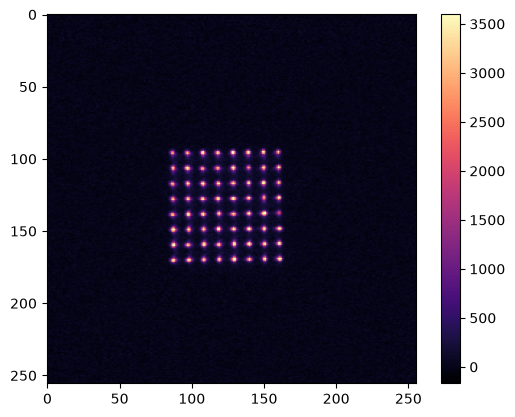

In [126]:
# Experiment and camera setup
n_iterations = 100
exp.set_motmaster_experiment("RbTweezerBasic2026_2")
exp.set_iterations(1)
hamcam.setup_acquisition("snap", 2)
imgs1, imgs2 = [], []
for i in range(n_iterations):
    hamcam.start_acquisition()
    exp.start_motmaster_experiment({
        "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
        "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
        "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"),
        "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
        "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"),
        "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
        "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"),
        "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
        "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
        "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
        "tTweezerSetVVA0": 0.0, "tTweezerSetVVA1": 0.0,
        "BackgroundDrop": 1})
    

    img1, img2 = hamcam.acquire_n_frames(2, broadcast=True)
    imgs1.append(img1)
    imgs2.append(img2)

img_average = an.tweezer_show_bg_subtracted(imgs1, imgs2, cmap='magma', show=True, vmaxfactor=0.6, show_grid=True)



Looking for trap sites...
64 Atoms Detected.
Parameter 'x_centre' set to 123.21875.
Parameter 'y_centre' set to 132.15625.
Parameters saved.


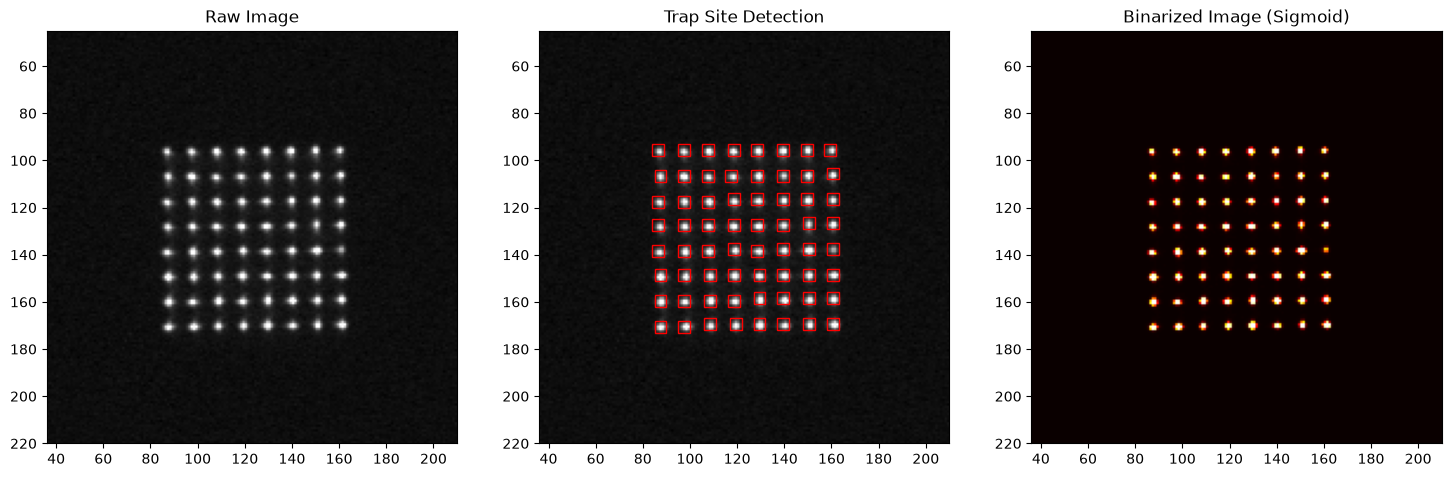

Trap (0) Loading Probability : 40.00 %
Trap (1) Loading Probability : 56.00 %
Trap (2) Loading Probability : 53.00 %
Trap (3) Loading Probability : 63.00 %
Trap (4) Loading Probability : 58.00 %
Trap (5) Loading Probability : 52.00 %
Trap (6) Loading Probability : 50.00 %
Trap (7) Loading Probability : 52.00 %
Trap (8) Loading Probability : 48.00 %
Trap (9) Loading Probability : 45.00 %
Trap (10) Loading Probability : 34.00 %
Trap (11) Loading Probability : 50.00 %
Trap (12) Loading Probability : 43.00 %
Trap (13) Loading Probability : 47.00 %
Trap (14) Loading Probability : 62.00 %
Trap (15) Loading Probability : 54.00 %
Trap (16) Loading Probability : 41.00 %
Trap (17) Loading Probability : 53.00 %
Trap (18) Loading Probability : 49.00 %
Trap (19) Loading Probability : 47.00 %
Trap (20) Loading Probability : 49.00 %
Trap (21) Loading Probability : 50.00 %
Trap (22) Loading Probability : 58.00 %
Trap (23) Loading Probability : 46.00 %
Trap (24) Loading Probability : 40.00 %
Trap (25) 

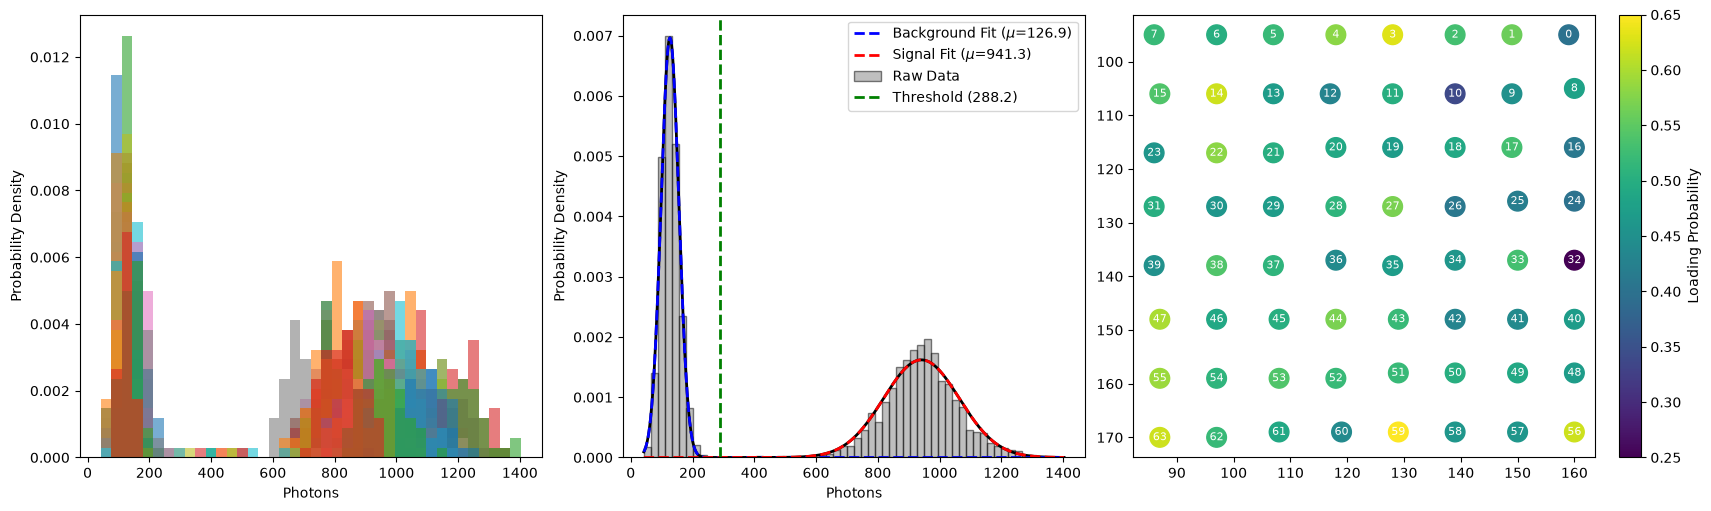

In [127]:
feature_size, window = 10, 5
grid_positions, detection_threshold = an.detect_trap_sites(img_average, 8*8, detection_step=100)
an.set_array_centre(grid_positions)
grid_positions = an.index_grid_positions(grid_positions, x_n1, y_n1)
an.visualize_results(img_average, grid_positions, margin=50, window_size=window, threshold=detection_threshold, vmaxfactor=0.5, bin_sharpness=20, bin_thresh_factor=0.9)
imgs_n_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs1]
photons, loading_probabilities, threshold_1, fidelity = an.get_array_loading_statistics(imgs_n_filtered, grid_positions, threshold=100, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=True, verbose=True, show_site_labels=True)